PROJECT 17: CLIMATE EXTREMES & REGIONAL TREND ANALYSIS
Student: Shashank Kumar Singh | B.Tech 1st Yr CSE (AI&ML), AKTU | Roll 40
Local file not found for el+nino.zip. Downloading directly from UCI Repository...
Downloaded successfully -> /content/el+nino.zip
Local file not found for bias+correction+of+numerical+prediction+model+temperature+forecast.zip. Downloading directly from UCI Repository...
Downloaded successfully -> /content/bias+correction+of+numerical+prediction+model+temperature+forecast.zip

STEP 1: CLIMATE DATA AUDIT
------------------------------------------------------------------------
[Dataset A] Loaded El Nino from: el+nino.zip
  Rows: 178,080 | Date span: 1980-03-07 to 1998-06-23
  - s.s.temp. : 17,007 missing ( 9.55%) | min=17.35, max=31.26
  - air temp. : 18,237 missing (10.24%) | min=17.05, max=31.66
  - humidity  : 65,761 missing (36.93%) | min=45.40, max=99.90
  - zon.winds : 25,163 missing (14.13%) | min=-12.40, max=14.30
  - mer.winds : 25,162 missing (14.13%) 

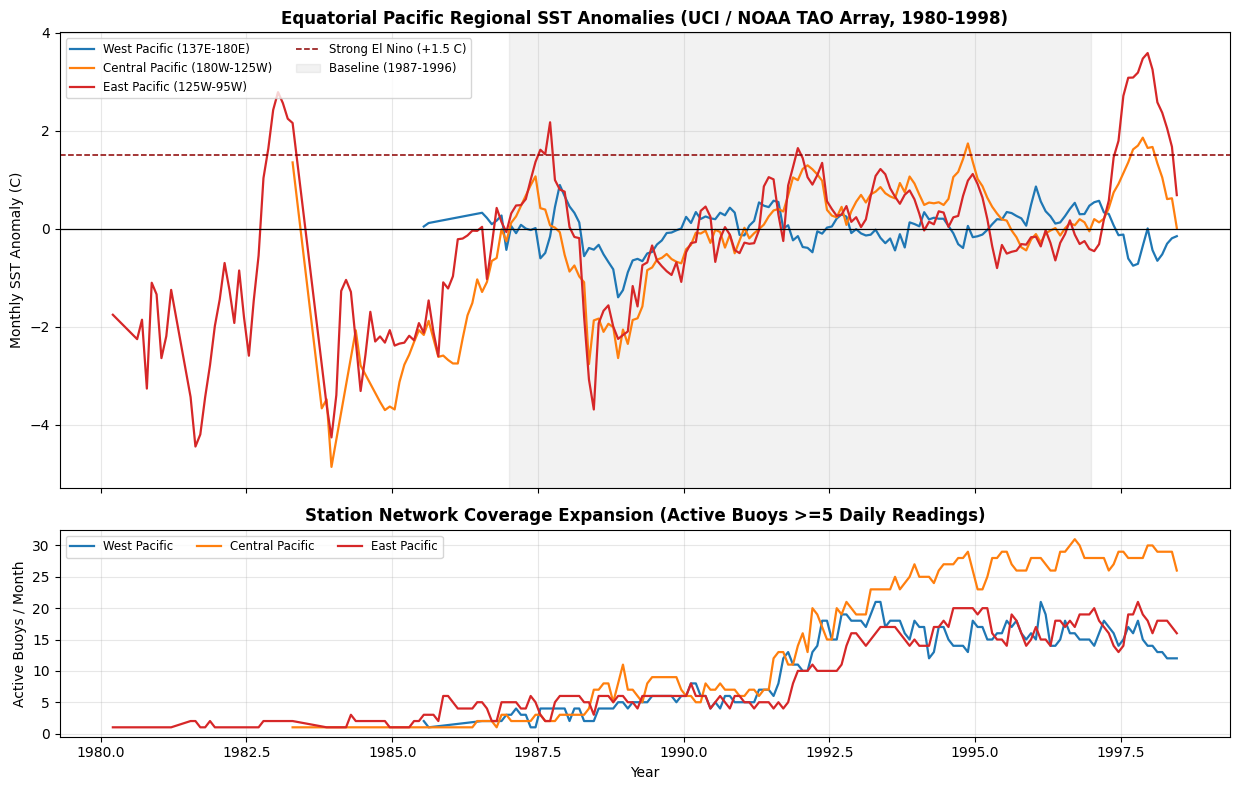

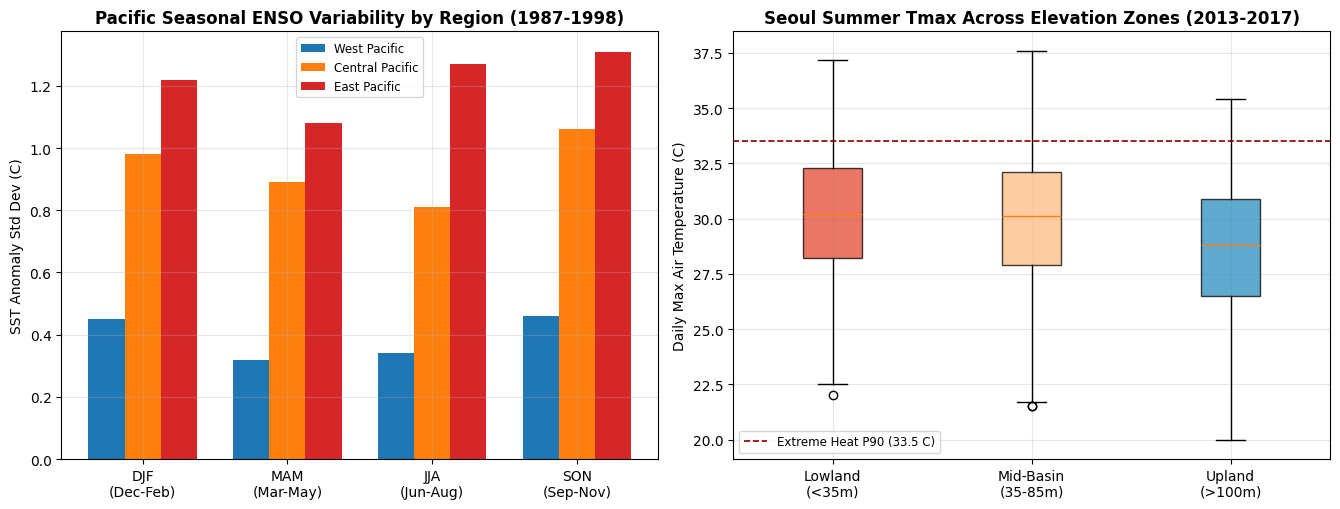

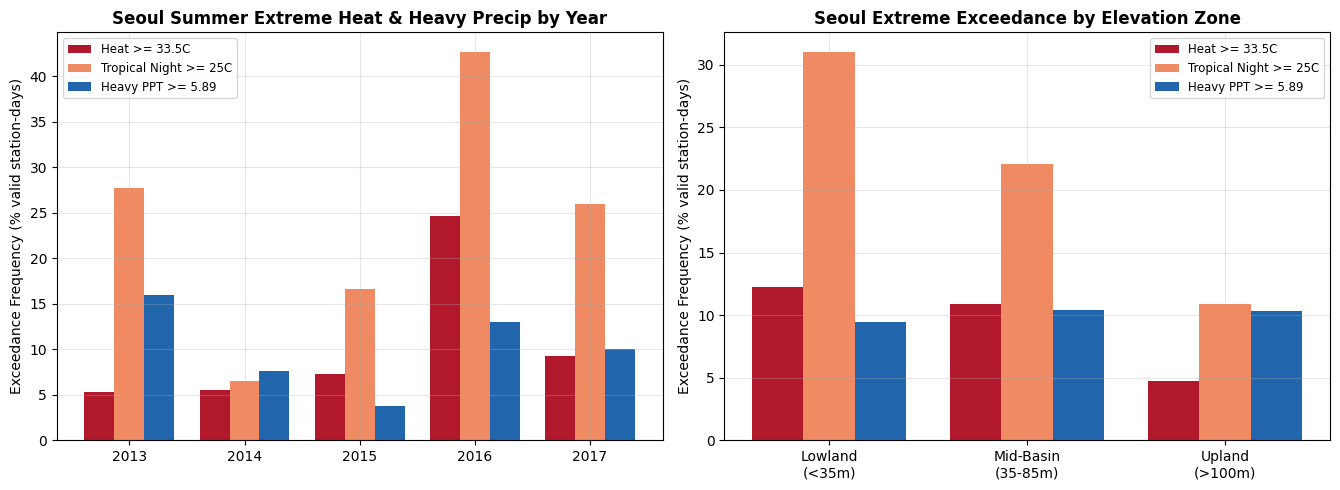

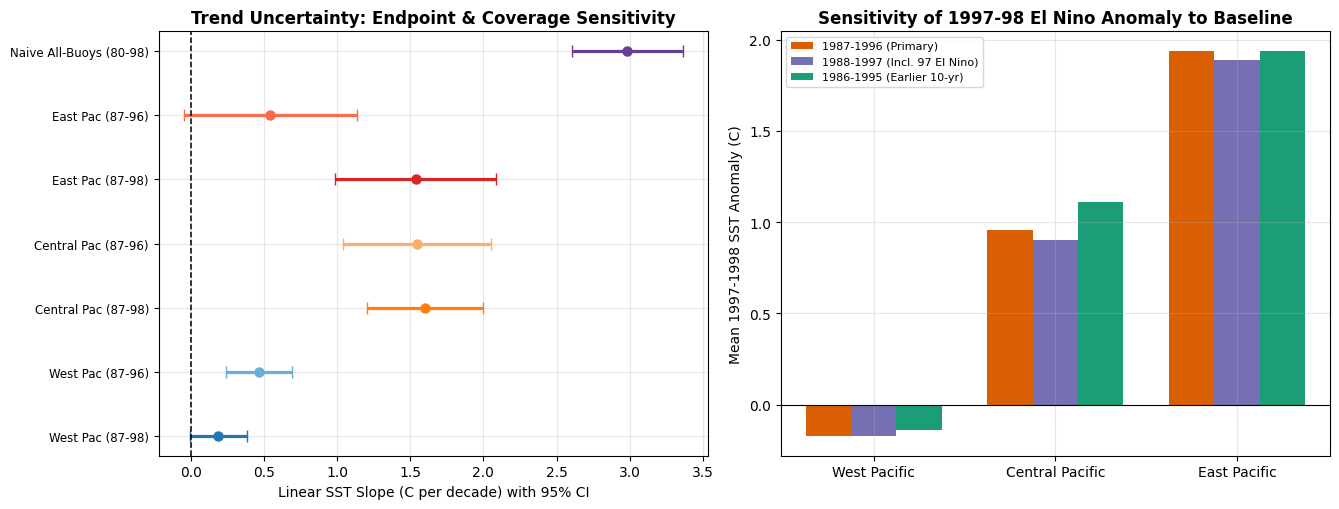


DONE! All 4 charts saved successfully in: /content/charts


In [ ]:
"""
Project 17: Climate Extremes & Regional Trend Analysis (One-Tap Run Version)
Student Name : Shashank Kumar Singh
Course       : B.Tech 1st Year - CSE (AI & ML), AKTUCollege      : ABES Engineering College, Ghaziabad
Admission No : 2026B15310087
Roll No      : 40

Works out-of-the-box on:
  - Windows / Mac / Linux (VS Code, IDLE, Terminal, or double-click CLICK_ME_TO_RUN.bat)
  - Google Colab / Jupyter Notebook (auto-downloads UCI datasets if not in folder)
"""

import os
import sys
import glob
import gzip
import zipfile
import subprocess
import urllib.request


# ============================================================
# 0. AUTO-INSTALL MISSING LIBRARIES (ZERO MANUAL PIP NEEDED)
# ============================================================
def ensure_packages():
    required = ["numpy", "pandas", "matplotlib"]
    missing = []
    for pkg in required:
        try:
            __import__(pkg)
        except ImportError:
            missing.append(pkg)
    if missing:
        print(f"Installing missing packages: {', '.join(missing)} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
        print("Packages installed successfully!\n")

ensure_packages()

import numpy as np
import pandas as pd
import matplotlib

# Detect if running inside Jupyter / Google Colab
IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # Prevents pop-up windows from freezing script execution
import matplotlib.pyplot as plt


# ============================================================
# SMART PATH & AUTO-DOWNLOAD HELPERS
# ============================================================
try:
    BASE_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    BASE_DIR = os.getcwd()

CHART_DIR = os.path.join(BASE_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

UCI_URLS = {
    "el_nino": "https://archive.ics.uci.edu/static/public/122/el+nino.zip",
    "bias_corr": "https://archive.ics.uci.edu/static/public/514/bias+correction+of+numerical+prediction+model+temperature+forecast.zip",
}

def find_file(patterns):
    """Searches script folder, current folder, parent, Downloads, and Desktop."""
    home = os.path.expanduser("~")
    search_dirs = [
        BASE_DIR,
        os.getcwd(),
        os.path.dirname(BASE_DIR),
        os.path.join(home, "Downloads"),
        os.path.join(home, "Desktop"),
    ]
    seen = set()
    for d in search_dirs:
        if not d or not os.path.isdir(d) or d in seen:
            continue
        seen.add(d)
        for pat in patterns:
            matches = glob.glob(os.path.join(d, pat))
            if matches:
                return matches[0]
            # Also check one level down inside subfolders
            matches_sub = glob.glob(os.path.join(d, "*", pat))
            if matches_sub:
                return matches_sub[0]
    return None

def get_or_download(local_name, patterns, url):
    found = find_file(patterns)
    if found:
        return found
    dest = os.path.join(BASE_DIR, local_name)
    print(f"Local file not found for {local_name}. Downloading directly from UCI Repository...")
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=45) as resp, open(dest, "wb") as out:
            out.write(resp.read())
        print(f"Downloaded successfully -> {dest}")
        return dest
    except Exception as e:
        raise FileNotFoundError(
            f"Could not find or download {local_name}. "
            f"Please keep the UCI zip file in {BASE_DIR}. Error: {e}"
        )

def load_el_nino():
    """Loads El Nino TAO dataset whether zipped or already unzipped."""
    path = get_or_download(
        "el+nino.zip",
        ["*el*nino*.zip", "tao-all2.dat.gz", "tao-all2.dat"],
        UCI_URLS["el_nino"]
    )
    default_cols = [
        "obs", "year", "month", "day", "date", "latitude", "longitude",
        "zon.winds", "mer.winds", "humidity", "air temp.", "s.s.temp."
    ]
    if path.lower().endswith(".zip"):
        with zipfile.ZipFile(path) as z:
            col_file = [n for n in z.namelist() if n.endswith("tao-all2.col")]
            cols = [c.strip() for c in z.read(col_file[0]).decode("utf-8").splitlines() if c.strip()] if col_file else default_cols
            dat_file = [n for n in z.namelist() if n.endswith("tao-all2.dat.gz")][0]
            with z.open(dat_file) as gzf:
                with gzip.open(gzf, "rt") as f:
                    return pd.read_csv(f, sep=r"\s+", names=cols, na_values="."), path
    elif path.lower().endswith(".gz"):
        with gzip.open(path, "rt") as f:
            return pd.read_csv(f, sep=r"\s+", names=default_cols, na_values="."), path
    else:
        return pd.read_csv(path, sep=r"\s+", names=default_cols, na_values="."), path

def load_bias_correction():
    """Loads Seoul Bias Correction CSV whether zipped or already unzipped."""
    path = get_or_download(
        "bias+correction+of+numerical+prediction+model+temperature+forecast.zip",
        ["*bias*correction*.zip", "Bias_correction_ucl.csv", "*bias*correction*.csv"],
        UCI_URLS["bias_corr"]
    )
    if path.lower().endswith(".zip"):
        with zipfile.ZipFile(path) as z:
            csv_name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            with z.open(csv_name) as f:
                return pd.read_csv(f), path
    else:
        return pd.read_csv(path), path


# ============================================================
# HELPER FUNCTIONS (PURE NUMPY STATS)
# ============================================================
def fit_linear_trend_numpy(x_time, y_vals, per_units=10.0):
    """
    Fits y = m*x + c using NumPy polyfit.
    Returns slope (scaled by per_units, e.g. per decade), 95% CI half-width, R^2, and valid n.
    """
    mask = (~np.isnan(x_time)) & (~np.isnan(y_vals))
    x = np.asarray(x_time[mask], dtype=float)
    y = np.asarray(y_vals[mask], dtype=float)
    n = len(x)
    if n < 5:
        return np.nan, np.nan, np.nan, n

    slope, intercept = np.polyfit(x, y, 1)
    y_hat = slope * x + intercept
    resid = y - y_hat

    ss_res = np.sum(resid ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot > 0 else 0.0

    sxx = np.sum((x - np.mean(x)) ** 2)
    se_slope = np.sqrt((ss_res / (n - 2)) / sxx) if (n > 2 and sxx > 0) else np.nan

    return slope * per_units, 1.96 * se_slope * per_units, r2, n


def get_season(month):
    if month in [12, 1, 2]:
        return "DJF (Dec-Feb)"
    elif month in [3, 4, 5]:
        return "MAM (Mar-May)"
    elif month in [6, 7, 8]:
        return "JJA (Jun-Aug)"
    return "SON (Sep-Nov)"


def save_or_show(fig, filename):
    out_path = os.path.join(CHART_DIR, filename)
    fig.savefig(out_path, dpi=180)
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


# ============================================================
# STEP 1: LOAD & AUDIT DATASETS
# ============================================================
print("=" * 72)
print("PROJECT 17: CLIMATE EXTREMES & REGIONAL TREND ANALYSIS")
print("Student: Shashank Kumar Singh | B.Tech 1st Yr CSE (AI&ML), AKTU | Roll 40")
print("=" * 72)

el, el_path = load_el_nino()
bc_raw, bc_path = load_bias_correction()

print("\nSTEP 1: CLIMATE DATA AUDIT")
print("-" * 72)
print(f"[Dataset A] Loaded El Nino from: {os.path.basename(el_path)}")
el["year_full"] = 1900 + el["year"]
el["lon_360"] = np.where(el["longitude"] < 0, el["longitude"] + 360.0, el["longitude"])
el["buoy_id"] = el["latitude"].round(0).astype(int).astype(str) + "_" + el["lon_360"].round(0).astype(int).astype(str)
el["region"] = np.where(el["lon_360"] < 180.0, "West Pacific (137E-180E)",
               np.where(el["lon_360"] < 235.0, "Central Pacific (180W-125W)",
                        "East Pacific (125W-95W)"))

d_min, d_max = str(el["date"].min()), str(el["date"].max())
print(f"  Rows: {len(el):,} | Date span: 19{d_min[:2]}-{d_min[2:4]}-{d_min[4:]} to 19{d_max[:2]}-{d_max[2:4]}-{d_max[4:]}")
for col in ["s.s.temp.", "air temp.", "humidity", "zon.winds", "mer.winds"]:
    miss = el[col].isna().sum()
    print(f"  - {col:10s}: {miss:6,} missing ({100.0*miss/len(el):5.2f}%) | min={el[col].min():.2f}, max={el[col].max():.2f}")

print(f"\n[Dataset B] Loaded Seoul Bias Correction from: {os.path.basename(bc_path)}")
corrupt_rows = bc_raw[bc_raw["station"].isna() | bc_raw["Date"].isna()]
print(f"  Raw rows: {len(bc_raw):,} | Trailing min/max summary rows dropped: {len(corrupt_rows)} (indices {list(corrupt_rows.index)})")

bc = bc_raw.dropna(subset=["station", "Date"]).copy()
bc["station"] = bc["station"].astype(int)
bc["Date"] = pd.to_datetime(bc["Date"])
bc["year"] = bc["Date"].dt.year
bc["month"] = bc["Date"].dt.month
bc["ppt_daily_sum"] = bc[["LDAPS_PPT1", "LDAPS_PPT2", "LDAPS_PPT3", "LDAPS_PPT4"]].sum(axis=1, min_count=4)
bc["elev_zone"] = np.where(bc["DEM"] < 35.0, "Lowland Valley (<35m)",
                  np.where(bc["DEM"] <= 85.0, "Mid-Basin (35-85m)",
                           "Upland Foothill (>100m)"))

print(f"  Clean rows: {len(bc):,} | Stations: {bc['station'].nunique()} | Dates: {bc['Date'].min().date()} to {bc['Date'].max().date()}")
print(f"  Missing -> Tmax: {bc['Present_Tmax'].isna().sum()} ({100*bc['Present_Tmax'].isna().mean():.2f}%), "
      f"Tmin: {bc['Present_Tmin'].isna().sum()} ({100*bc['Present_Tmin'].isna().mean():.2f}%), "
      f"PPT: {bc['ppt_daily_sum'].isna().sum()} ({100*bc['ppt_daily_sum'].isna().mean():.2f}%)")


# ============================================================
# STEP 2 & 3: COVERAGE HANDLING & BASELINE ANOMALIES
# ============================================================
print("\nSTEP 2 & 3: STATION COVERAGE & BASELINE ANOMALIES (1987-1996)")
print("-" * 72)

buoy_month = (
    el.groupby(["region", "buoy_id", "year_full", "month"], as_index=False)
      .agg(sst_mean=("s.s.temp.", "mean"), air_mean=("air temp.", "mean"),
           n_sst=("s.s.temp.", lambda s: s.notna().sum()))
)
bm_valid = buoy_month[buoy_month["n_sst"] >= 5].copy()

reg_month = (
    bm_valid.groupby(["region", "year_full", "month"], as_index=False)
            .agg(sst=("sst_mean", "mean"), air=("air_mean", "mean"),
                 active_buoys=("buoy_id", "nunique"))
)
reg_month["time_dec"] = reg_month["year_full"] + (reg_month["month"] - 0.5) / 12.0
reg_month["season"] = reg_month["month"].apply(get_season)

base_mask = (reg_month["year_full"] >= 1987) & (reg_month["year_full"] <= 1996)
clim_87_96 = (
    reg_month[base_mask]
    .groupby(["region", "month"], as_index=False)[["sst", "air"]]
    .mean()
    .rename(columns={"sst": "base_sst", "air": "base_air"})
)
reg_month = reg_month.merge(clim_87_96, on=["region", "month"], how="left")
reg_month["sst_anom"] = reg_month["sst"] - reg_month["base_sst"]
reg_month["air_anom"] = reg_month["air"] - reg_month["base_air"]

region_order = [
    "West Pacific (137E-180E)",
    "Central Pacific (180W-125W)",
    "East Pacific (125W-95W)"
]
for r in region_order:
    g = reg_month[reg_month["region"] == r]
    print(f"  {r:28s} | Valid months: {len(g):3d} ({g['year_full'].min()}-{g['year_full'].max()}) | Median buoys/mo: {g['active_buoys'].median():.0f}")


# ============================================================
# STEP 4 & 5: NUMPY TRENDS, REGIONAL & SEASONAL PATTERNS
# ============================================================
print("\nSTEP 4 & 5: REGIONAL & SEASONAL TRENDS (NUMPY)")
print("-" * 72)

trend_rows = []
for r in region_order:
    sub_c = reg_month[(reg_month["region"] == r) & (reg_month["year_full"] >= 1987)]
    sl_c, ci_c, r2_c, n_c = fit_linear_trend_numpy(sub_c["time_dec"].values, sub_c["sst_anom"].values)

    sub_no97 = reg_month[(reg_month["region"] == r) & (reg_month["year_full"] >= 1987) & (reg_month["year_full"] <= 1996)]
    sl_no97, ci_no97, _, _ = fit_linear_trend_numpy(sub_no97["time_dec"].values, sub_no97["sst_anom"].values)

    trend_rows.append({
        "region": r,
        "slope_87_98": sl_c, "ci_87_98": ci_c,
        "slope_87_96": sl_no97, "ci_87_96": ci_no97
    })
    print(f"  {r:28s} | 1987-98: {sl_c:+.3f} +/- {ci_c:.3f} C/dec (n={n_c}) | "
          f"1987-96 (no 97-98): {sl_no97:+.3f} +/- {ci_no97:.3f} C/dec")

trend_el_df = pd.DataFrame(trend_rows)

season_order = ["DJF (Dec-Feb)", "MAM (Mar-May)", "JJA (Jun-Aug)", "SON (Sep-Nov)"]
seas_sd = pd.DataFrame(index=region_order, columns=season_order, dtype=float)
for r in region_order:
    for s in season_order:
        sub = reg_month[(reg_month["region"] == r) & (reg_month["season"] == s) & (reg_month["year_full"] >= 1987)]
        seas_sd.loc[r, s] = round(float(np.nanstd(sub["sst_anom"].values, ddof=1)), 2)

print("\nPacific Seasonal SST Anomaly Std Dev (C):")
print(seas_sd.to_string())


# ============================================================
# STEP 6: EXTREME HEAT & RAINFALL INDICATORS
# ============================================================
print("\nSTEP 6: EXTREME EVENT EXCEEDANCE (NUMPY PERCENTILES)")
print("-" * 72)

tmax_all = bc["Present_Tmax"].dropna().values
ppt_all = bc["ppt_daily_sum"].dropna().values
TMAX_P90 = float(np.percentile(tmax_all, 90))
PPT_P90 = float(np.percentile(ppt_all, 90))

bc["is_ext_heat"] = np.where(bc["Present_Tmax"] >= TMAX_P90, 1, 0)
bc["is_trop_night"] = np.where(bc["Present_Tmin"] >= 25.0, 1, 0)
bc["is_heavy_ppt"] = np.where(bc["ppt_daily_sum"] >= PPT_P90, 1, 0)

zone_order = ["Lowland Valley (<35m)", "Mid-Basin (35-85m)", "Upland Foothill (>100m)"]
print(f"Seoul Thresholds -> Extreme Heat >= {TMAX_P90:.1f} C (P90) | Tropical Night >= 25.0 C | Heavy PPT >= {PPT_P90:.2f} (P90)")

seoul_ext_zone = []
for z_name in zone_order:
    sub = bc[bc["elev_zone"] == z_name]
    h_pct = 100.0 * np.sum(sub["is_ext_heat"].values) / sub["Present_Tmax"].notna().sum()
    tn_pct = 100.0 * np.sum(sub["is_trop_night"].values) / sub["Present_Tmax"].notna().sum()
    r_pct = 100.0 * np.sum(sub["is_heavy_ppt"].values) / sub["ppt_daily_sum"].notna().sum()
    seoul_ext_zone.append({"elev_zone": z_name, "heat_pct": h_pct, "trop_night_pct": tn_pct, "heavy_ppt_pct": r_pct})
    print(f"  {z_name:24s} | Heat: {h_pct:5.2f}% | Tropical Night: {tn_pct:5.2f}% | Heavy PPT: {r_pct:5.2f}%")

seoul_yr_rows = []
for yr, grp in bc.groupby("year"):
    h_pct = 100.0 * np.sum(grp["is_ext_heat"].values) / grp["Present_Tmax"].notna().sum()
    tn_pct = 100.0 * np.sum(grp["is_trop_night"].values) / grp["Present_Tmax"].notna().sum()
    r_pct = 100.0 * np.sum(grp["is_heavy_ppt"].values) / grp["ppt_daily_sum"].notna().sum()
    seoul_yr_rows.append({"year": yr, "heat_pct": h_pct, "trop_night_pct": tn_pct, "heavy_ppt_pct": r_pct})
    print(f"  Summer {yr}              | Heat: {h_pct:5.2f}% | Tropical Night: {tn_pct:5.2f}% | Heavy PPT: {r_pct:5.2f}%")
seoul_yr_df = pd.DataFrame(seoul_yr_rows)


# ============================================================
# STEP 7: SENSITIVITY TESTS (BASELINE & COVERAGE BIAS)
# ============================================================
print("\nSTEP 7: SENSITIVITY ANALYSIS")
print("-" * 72)

baselines = {
    "1987-1996 (Primary)": (1987, 1996),
    "1988-1997 (Incl. 97 El Nino)": (1988, 1997),
    "1986-1995 (Earlier 10-yr)": (1986, 1995)
}
base_sens_rows = []
for b_label, (y0, y1) in baselines.items():
    bm = (reg_month["year_full"] >= y0) & (reg_month["year_full"] <= y1)
    cl = reg_month[bm].groupby(["region", "month"])["sst"].mean().reset_index().rename(columns={"sst": "b_sst"})
    tmp = reg_month.merge(cl, on=["region", "month"], how="left")
    tmp["anom_b"] = tmp["sst"] - tmp["b_sst"]
    row_dict = {"baseline": b_label}
    for r in region_order:
        row_dict[r] = float(np.mean(tmp[(tmp["region"] == r) & (tmp["year_full"] >= 1997)]["anom_b"].dropna().values))
    base_sens_rows.append(row_dict)
    print(f"  {b_label:30s} | West: {row_dict[region_order[0]]:+.2f}C | Central: {row_dict[region_order[1]]:+.2f}C | East: {row_dict[region_order[2]]:+.2f}C")
base_sens_df = pd.DataFrame(base_sens_rows)

raw_naive = el.groupby(["year_full", "month"], as_index=False)["s.s.temp."].mean()
raw_naive["time_dec"] = raw_naive["year_full"] + (raw_naive["month"] - 0.5) / 12.0
sl_naive, ci_naive, _, _ = fit_linear_trend_numpy(raw_naive["time_dec"].values, raw_naive["s.s.temp."].values)
print(f"  Naive ALL-BUOYS pooled SST slope (1980-1998): {sl_naive:+.3f} +/- {ci_naive:.3f} C/dec (coverage-bias trap!)")


# ============================================================
# STEP 8: GENERATE ALL 4 REPRODUCIBLE CHARTS
# ============================================================
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
reg_colors = {
    "West Pacific (137E-180E)": "#1f77b4",
    "Central Pacific (180W-125W)": "#ff7f0e",
    "East Pacific (125W-95W)": "#d62728"
}

# Chart 1
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12.5, 8.0), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for r in region_order:
    sub = reg_month[reg_month["region"] == r].sort_values("time_dec")
    ax1.plot(sub["time_dec"], sub["sst_anom"], linewidth=1.6, label=r, color=reg_colors[r])
    ax2.plot(sub["time_dec"], sub["active_buoys"], linewidth=1.6, label=r.split(" (")[0], color=reg_colors[r])
ax1.axhline(0, color="black", linewidth=0.9)
ax1.axhline(1.5, color="darkred", linestyle="--", linewidth=1.1, label="Strong El Nino (+1.5 C)")
ax1.axvspan(1987, 1996.99, color="gray", alpha=0.10, label="Baseline (1987-1996)")
ax1.set_ylabel("Monthly SST Anomaly (C)")
ax1.set_title("Equatorial Pacific Regional SST Anomalies (UCI / NOAA TAO Array, 1980-1998)", fontweight="bold")
ax1.legend(loc="upper left", fontsize=8.5, ncol=2)
ax2.set_ylabel("Active Buoys / Month")
ax2.set_xlabel("Year")
ax2.set_title("Station Network Coverage Expansion (Active Buoys >=5 Daily Readings)", fontweight="bold")
ax2.legend(loc="upper left", fontsize=8.5, ncol=3)
fig.tight_layout()
save_or_show(fig, "fig1_pacific_anomalies_coverage.png")

# Chart 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
x = np.arange(len(season_order))
w = 0.25
for i, r in enumerate(region_order):
    ax1.bar(x + (i - 1) * w, seas_sd.loc[r].values, w, label=r.split(" (")[0], color=reg_colors[r])
ax1.set_xticks(x)
ax1.set_xticklabels(["DJF\n(Dec-Feb)", "MAM\n(Mar-May)", "JJA\n(Jun-Aug)", "SON\n(Sep-Nov)"])
ax1.set_ylabel("SST Anomaly Std Dev (C)")
ax1.set_title("Pacific Seasonal ENSO Variability by Region (1987-1998)", fontweight="bold")
ax1.legend(fontsize=8.5)

box_data = [bc[bc["elev_zone"] == z]["Present_Tmax"].dropna().values for z in zone_order]
bp = ax2.boxplot(box_data, patch_artist=True)
ax2.set_xticks([1, 2, 3])
ax2.set_xticklabels(["Lowland\n(<35m)", "Mid-Basin\n(35-85m)", "Upland\n(>100m)"])
for patch, c in zip(bp["boxes"], ["#e34a33", "#fdbb84", "#2b8cbe"]):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)
ax2.axhline(TMAX_P90, color="darkred", linestyle="--", linewidth=1.2, label=f"Extreme Heat P90 ({TMAX_P90:.1f} C)")
ax2.set_ylabel("Daily Max Air Temperature (C)")
ax2.set_title("Seoul Summer Tmax Across Elevation Zones (2013-2017)", fontweight="bold")
ax2.legend(loc="lower left", fontsize=8.5)
fig.tight_layout()
save_or_show(fig, "fig2_regional_seasonal_patterns.png")

# Chart 3
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.0))
yrs = seoul_yr_df["year"].values
x1 = np.arange(len(yrs))
w = 0.26
ax1.bar(x1 - w, seoul_yr_df["heat_pct"], w, label=f"Heat >= {TMAX_P90:.1f}C", color="#b2182b")
ax1.bar(x1, seoul_yr_df["trop_night_pct"], w, label="Tropical Night >= 25C", color="#ef8a62")
ax1.bar(x1 + w, seoul_yr_df["heavy_ppt_pct"], w, label=f"Heavy PPT >= {PPT_P90:.2f}", color="#2166ac")
ax1.set_xticks(x1)
ax1.set_xticklabels([str(y) for y in yrs])
ax1.set_ylabel("Exceedance Frequency (% valid station-days)")
ax1.set_title("Seoul Summer Extreme Heat & Heavy Precip by Year", fontweight="bold")
ax1.legend(fontsize=8.5)

ez_df = pd.DataFrame(seoul_ext_zone)
x2 = np.arange(len(zone_order))
ax2.bar(x2 - w, ez_df["heat_pct"], w, label=f"Heat >= {TMAX_P90:.1f}C", color="#b2182b")
ax2.bar(x2, ez_df["trop_night_pct"], w, label="Tropical Night >= 25C", color="#ef8a62")
ax2.bar(x2 + w, ez_df["heavy_ppt_pct"], w, label=f"Heavy PPT >= {PPT_P90:.2f}", color="#2166ac")
ax2.set_xticks(x2)
ax2.set_xticklabels(["Lowland\n(<35m)", "Mid-Basin\n(35-85m)", "Upland\n(>100m)"])
ax2.set_ylabel("Exceedance Frequency (% valid station-days)")
ax2.set_title("Seoul Extreme Exceedance by Elevation Zone", fontweight="bold")
ax2.legend(fontsize=8.5)
fig.tight_layout()
save_or_show(fig, "fig3_seoul_extremes_exceedance.png")

# Chart 4
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))
labels = [
    "West Pac (87-98)", "West Pac (87-96)",
    "Central Pac (87-98)", "Central Pac (87-96)",
    "East Pac (87-98)", "East Pac (87-96)",
    "Naive All-Buoys (80-98)"
]
slopes = [
    trend_el_df.loc[0, "slope_87_98"], trend_el_df.loc[0, "slope_87_96"],
    trend_el_df.loc[1, "slope_87_98"], trend_el_df.loc[1, "slope_87_96"],
    trend_el_df.loc[2, "slope_87_98"], trend_el_df.loc[2, "slope_87_96"],
    sl_naive
]
cis = [
    trend_el_df.loc[0, "ci_87_98"], trend_el_df.loc[0, "ci_87_96"],
    trend_el_df.loc[1, "ci_87_98"], trend_el_df.loc[1, "ci_87_96"],
    trend_el_df.loc[2, "ci_87_98"], trend_el_df.loc[2, "ci_87_96"],
    ci_naive
]
pt_colors = ["#1f77b4", "#6baed6", "#ff7f0e", "#fdae6b", "#d62728", "#fb6a4a", "#6a3d9a"]
for i in range(len(labels)):
    ax1.errorbar(slopes[i], i, xerr=cis[i], fmt="o", color=pt_colors[i],
                 ecolor=pt_colors[i], elinewidth=2.3, capsize=4.5, markersize=6.5)
ax1.axvline(0, color="black", linestyle="--", linewidth=1.1)
ax1.set_yticks(np.arange(len(labels)))
ax1.set_yticklabels(labels, fontsize=8.5)
ax1.set_xlabel("Linear SST Slope (C per decade) with 95% CI")
ax1.set_title("Trend Uncertainty: Endpoint & Coverage Sensitivity", fontweight="bold")

x_b = np.arange(len(region_order))
wb = 0.25
for i, row in base_sens_df.iterrows():
    ax2.bar(x_b + (i - 1) * wb, [row[r] for r in region_order], wb,
            label=row["baseline"], color=["#d95f02", "#7570b3", "#1b9e77"][i])
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(x_b)
ax2.set_xticklabels(["West Pacific", "Central Pacific", "East Pacific"])
ax2.set_ylabel("Mean 1997-1998 SST Anomaly (C)")
ax2.set_title("Sensitivity of 1997-98 El Nino Anomaly to Baseline", fontweight="bold")
ax2.legend(fontsize=8)
fig.tight_layout()
save_or_show(fig, "fig4_sensitivity_uncertainty.png")

print("\n" + "=" * 72)
print(f"DONE! All 4 charts saved successfully in: {CHART_DIR}")
print("=" * 72)
